In [1]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt

print("Python-Umgebung erfolgreich gestartet!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Python-Umgebung erfolgreich gestartet!
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1


In [2]:
import pandas as pd

url = "https://huggingface.co/datasets/claritystorm/cfpb-consumer-complaints/resolve/main/sample_1000.csv"

df = pd.read_csv(url)

print("Datensatz erfolgreich geladen!")
print("Größe:", df.shape)

print("\nVorhandene Spalten:")
print(df.columns.tolist())

print("\nErste 5 Einträge:")
display(df.head())

print("\nVorhandene Beschwerdetexte:")
print(df["consumer_narrative"].notna().sum())

Datensatz erfolgreich geladen!
Größe: (1000, 22)

Vorhandene Spalten:
['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'consumer_narrative', 'company_public_response', 'company', 'state', 'zip_code', 'tags', 'consumer_consent', 'submitted_via', 'date_sent_to_company', 'company_response', 'timely_response', 'consumer_disputed', 'complaint_id', 'year', 'month', 'has_narrative', 'product_normalised']

Erste 5 Einträge:


,date_received,product,sub_product,issue,sub_issue,consumer_narrative,company_public_response,company,state,zip_code,...,submitted_via,date_sent_to_company,company_response,timely_response,consumer_disputed,complaint_id,year,month,has_narrative,product_normalised
0,2023-08-28,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't...,NaN,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,WI,53143.0,...,Web,2023-08-28,Closed with non-monetary relief,1,NaN,7463130,2023,8,0,Credit reporting or other personal consumer re...
1,2025-03-06,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Information belongs to someone else,I have not supplied proof under the doctrine o...,Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",NJ,8046.0,...,Web,2025-03-06,Closed with non-monetary relief,1,NaN,12351479,2025,3,1,Credit reporting or other personal consumer re...
2,2020-04-08,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Information belongs to someone else,NaN,NaN,"EQUIFAX, INC.",NC,28277.0,...,Web,2020-04-08,Closed with explanation,1,NaN,3598008,2020,4,0,Credit reporting / repair
3,2025-04-25,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Information belongs to someone else,NaN,NaN,"EQUIFAX, INC.",SC,29680.0,...,Web,2025-04-25,Closed with non-monetary relief,1,NaN,13183092,2025,4,0,Credit reporting or other personal consumer re...
4,2018-05-16,Debt collection,I do not know,Written notification about debt,Didn't receive enough information to verify debt,NaN,Company has responded to the consumer and the ...,"JH Portfolio Debt Equities, LLC",FL,33901.0,...,Postal mail,2018-05-16,Closed with explanation,1,NaN,2909081,2018,5,0,Debt collection



Vorhandene Beschwerdetexte:
271


In [3]:
# Fehlende und leere Beschwerdetexte überprüfen
missing = df["consumer_narrative"].isna().sum()
empty = df["consumer_narrative"].fillna("").str.strip().eq("").sum()
duplicates = df["consumer_narrative"].dropna().duplicated().sum()

print("Gesamtzahl der Datensätze:", len(df))
print("Fehlende Beschwerdetexte:", missing)
print("Leere Beschwerdetexte:", empty)
print("Doppelte Beschwerdetexte:", duplicates)

# Länge der vorhandenen Beschwerdetexte untersuchen
text_lengths = df["consumer_narrative"].dropna().str.len()

print("\nDurchschnittliche Textlänge:", round(text_lengths.mean(), 2))
print("Kürzester Text:", text_lengths.min())
print("Längster Text:", text_lengths.max())

Gesamtzahl der Datensätze: 1000
Fehlende Beschwerdetexte: 729
Leere Beschwerdetexte: 729
Doppelte Beschwerdetexte: 5

Durchschnittliche Textlänge: 1040.63
Kürzester Text: 39
Längster Text: 28917


In [4]:
# Datensätze ohne Beschwerdetext entfernen
df_nlp = df.dropna(subset=["consumer_narrative"]).copy()

# Leerzeichen am Anfang und Ende entfernen
df_nlp["consumer_narrative"] = df_nlp["consumer_narrative"].str.strip()

# Leere Texte entfernen
df_nlp = df_nlp[df_nlp["consumer_narrative"] != ""]

# Doppelte Beschwerdetexte entfernen
df_nlp = df_nlp.drop_duplicates(subset=["consumer_narrative"])

# Ergebnis überprüfen
print("Datensätze nach der Bereinigung:", len(df_nlp))
print("\nErste 3 Beschwerdetexte:")
display(df_nlp[["consumer_narrative"]].head(3))

Datensätze nach der Bereinigung: 266

Erste 3 Beschwerdetexte:


,consumer_narrative
1,I have not supplied proof under the doctrine o...
6,Pursuant to 15 USC 1681a ( 2 ) ( B ) any autho...
7,I have a goal of getting a house as soon as po...


In [5]:
import re

# Funktion zur Textbereinigung
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# Bereinigte Texte in neuer Spalte speichern
df_nlp["cleaned_text"] = df_nlp["consumer_narrative"].apply(clean_text)

# Original und bereinigten Text vergleichen
display(df_nlp[["consumer_narrative", "cleaned_text"]].head(3))


,consumer_narrative,cleaned_text
1,I have not supplied proof under the doctrine o...,i have not supplied proof under the doctrine o...
6,Pursuant to 15 USC 1681a ( 2 ) ( B ) any autho...,pursuant to usc a b any authorization or appro...
7,I have a goal of getting a house as soon as po...,i have a goal of getting a house as soon as po...


In [6]:
# Prüfen, ob nach der Bereinigung leere Texte entstanden sind
empty_cleaned = (df_nlp["cleaned_text"] == "").sum()

print("Leere Texte nach der Bereinigung:", empty_cleaned)
print("Anzahl aller Beschwerdetexte:", len(df_nlp))

Leere Texte nach der Bereinigung: 0
Anzahl aller Beschwerdetexte: 266


In [7]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# CountVectorizer: Wörter zählen
count_vectorizer = CountVectorizer(stop_words="english")
count_matrix = count_vectorizer.fit_transform(df_nlp["cleaned_text"])

# TF-IDF: Wichtigkeit der Wörter berechnen
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(df_nlp["cleaned_text"])

# Ergebnisse vergleichen
print("Anzahl der Beschwerdetexte:", len(df_nlp))

print("\nCountVectorizer:")
print("Größe der Matrix:", count_matrix.shape)
print("Anzahl unterschiedlicher Wörter:", len(count_vectorizer.get_feature_names_out()))

print("\nTF-IDF:")
print("Größe der Matrix:", tfidf_matrix.shape)
print("Anzahl unterschiedlicher Wörter:", len(tfidf_vectorizer.get_feature_names_out()))

Anzahl der Beschwerdetexte: 266

CountVectorizer:
Größe der Matrix: (266, 3302)
Anzahl unterschiedlicher Wörter: 3302

TF-IDF:
Größe der Matrix: (266, 3302)
Anzahl unterschiedlicher Wörter: 3302


In [8]:
# Die 15 häufigsten Wörter mit CountVectorizer
count_words = count_vectorizer.get_feature_names_out()
count_frequency = count_matrix.sum(axis=0).A1

count_top = sorted(
    zip(count_words, count_frequency),
    key=lambda x: x[1],
    reverse=True
)[:15]

print("15 häufigste Wörter (CountVectorizer):")
for word, frequency in count_top:
    print(word, ":", frequency)


# Die 15 wichtigsten Wörter nach TF-IDF
tfidf_words = tfidf_vectorizer.get_feature_names_out()
tfidf_scores = tfidf_matrix.mean(axis=0).A1

tfidf_top = sorted(
    zip(tfidf_words, tfidf_scores),
    key=lambda x: x[1],
    reverse=True
)[:15]

print("\n15 wichtigste Wörter (TF-IDF):")
for word, score in tfidf_top:
    print(word, ":", round(score, 4))

15 häufigste Wörter (CountVectorizer):
xxxx : 3325
xx : 723
credit : 500
account : 389
information : 319
report : 283
reporting : 242
consumer : 235
payment : 154
debt : 140
accounts : 129
section : 117
loan : 112
financial : 110
date : 102

15 wichtigste Wörter (TF-IDF):
xxxx : 0.2337
xx : 0.0679
credit : 0.0612
account : 0.0527
report : 0.0469
reporting : 0.0399
information : 0.0388
accounts : 0.0314
consumer : 0.0307
debt : 0.0263
payment : 0.026
section : 0.0212
late : 0.0209
inaccurate : 0.0199
card : 0.0191


In [9]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Englische Stopwords um Platzhalter erweitern
custom_stopwords = list(ENGLISH_STOP_WORDS.union({"xxxx", "xx"}))

# CountVectorizer neu erstellen
count_vectorizer = CountVectorizer(stop_words=custom_stopwords)
count_matrix = count_vectorizer.fit_transform(df_nlp["cleaned_text"])

# TF-IDF neu erstellen
tfidf_vectorizer = TfidfVectorizer(stop_words=custom_stopwords)
tfidf_matrix = tfidf_vectorizer.fit_transform(df_nlp["cleaned_text"])

print("Neue Anzahl unterschiedlicher Wörter:")
print("CountVectorizer:", len(count_vectorizer.get_feature_names_out()))
print("TF-IDF:", len(tfidf_vectorizer.get_feature_names_out()))

Neue Anzahl unterschiedlicher Wörter:
CountVectorizer: 3300
TF-IDF: 3300


In [10]:
# Die 15 häufigsten Wörter nach der Bereinigung
count_words = count_vectorizer.get_feature_names_out()
count_frequency = count_matrix.sum(axis=0).A1

count_top = sorted(
    zip(count_words, count_frequency),
    key=lambda x: x[1],
    reverse=True
)[:15]

print("15 häufigste Wörter nach der Bereinigung:")

for word, frequency in count_top:
    print(word, ":", frequency)


15 häufigste Wörter nach der Bereinigung:
credit : 500
account : 389
information : 319
report : 283
reporting : 242
consumer : 235
payment : 154
debt : 140
accounts : 129
section : 117
loan : 112
financial : 110
date : 102
received : 102
act : 97


In [11]:
from sklearn.decomposition import LatentDirichletAllocation, NMF

# Anzahl der Themen für den ersten Test
n_topics = 5

# LDA-Modell erstellen und trainieren
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=20
)

lda_model.fit(count_matrix)

# NMF-Modell erstellen und trainieren
nmf_model = NMF(
    n_components=n_topics,
    random_state=42,
    init="nndsvda",
    max_iter=400
)

nmf_model.fit(tfidf_matrix)

print("Beide Themenmodelle wurden erfolgreich trainiert!")

Beide Themenmodelle wurden erfolgreich trainiert!


In [12]:
# Funktion zur Anzeige der wichtigsten Wörter je Thema
def show_topics(model, feature_names, n_top_words=10):
    for topic_idx, topic in enumerate(model.components_):
        top_words = [
            feature_names[i]
            for i in topic.argsort()[:-n_top_words - 1:-1]
        ]

        print(f"Thema {topic_idx + 1}: {', '.join(top_words)}")


# Themen von LDA anzeigen
print("THEMENANALYSE MIT LDA:")
show_topics(lda_model, count_vectorizer.get_feature_names_out())

print("\nTHEMENANALYSE MIT NMF:")
show_topics(nmf_model, tfidf_vectorizer.get_feature_names_out())

THEMENANALYSE MIT LDA:
Thema 1: credit, information, account, consumer, reporting, report, section, act, financial, date
Thema 2: credit, report, loan, accounts, balance, items, card, payments, information, complaint
Thema 3: account, payment, received, bank, did, told, loan, year, asked, email
Thema 4: payment, company, time, copy, check, received, credit, called, make, card
Thema 5: debt, letter, experian, credit, proof, report, collect, sent, owe, dispute

THEMENANALYSE MIT NMF:
Thema 1: credit, report, accounts, items, information, reporting, remove, removed, file, theft
Thema 2: section, consumer, states, reporting, agency, account, furnish, privacy, violated, instructions
Thema 3: account, bank, card, opened, number, closed, date, received, did, told
Thema 4: debt, proof, alleged, xxxxxxxx, collection, exist, pressume, doctrine, silence, supplied
Thema 5: late, payment, payments, reporting, credit, paid, loan, days, error, time


In [13]:
def clean_text(text):
    text = text.lower()

    # Internetadressen entfernen
    text = re.sub(r"http\S+|www\S+", "", text)

    # Anonymisierungsplatzhalter aus x entfernen
    text = re.sub(r"\bx{2,}\b", " ", text)

    # Sonderzeichen und Zahlen entfernen
    text = re.sub(r"[^a-z\s]", " ", text)

    # Mehrere Leerzeichen zusammenfassen
    text = re.sub(r"\s+", " ", text)

    return text.strip()


# Bereinigung erneut durchführen
df_nlp["cleaned_text"] = df_nlp["consumer_narrative"].apply(clean_text)

# Vektorisierung erneut durchführen
count_matrix = count_vectorizer.fit_transform(df_nlp["cleaned_text"])
tfidf_matrix = tfidf_vectorizer.fit_transform(df_nlp["cleaned_text"])

print("Platzhalter entfernt und Vektorisierung aktualisiert.")

Platzhalter entfernt und Vektorisierung aktualisiert.


In [14]:
# Anzahl der Themen für den ersten Test
n_topics = 5

# LDA erneut trainieren
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=20
)

lda_model.fit(count_matrix)

# NMF erneut trainieren
nmf_model = NMF(
    n_components=n_topics,
    random_state=42,
    init="nndsvda",
    max_iter=400
)

nmf_model.fit(tfidf_matrix)

print("LDA und NMF wurden erneut trainiert!")

LDA und NMF wurden erneut trainiert!


In [15]:
print("THEMENANALYSE MIT LDA:")
show_topics(lda_model, count_vectorizer.get_feature_names_out())

print("\nTHEMENANALYSE MIT NMF:")
show_topics(nmf_model, tfidf_vectorizer.get_feature_names_out())


THEMENANALYSE MIT LDA:
Thema 1: consumer, financial, information, credit, section, institution, act, personal, title, shall
Thema 2: credit, reporting, report, account, information, consumer, debt, accounts, inaccurate, date
Thema 3: account, payment, bank, closed, did, loan, received, year, time, told
Thema 4: account, report, credit, opened, experian, accounts, card, file, balance, theft
Thema 5: credit, received, payment, account, loan, asked, pay, email, did, told

THEMENANALYSE MIT NMF:
Thema 1: credit, report, accounts, items, information, reporting, remove, removed, file, theft
Thema 2: section, consumer, states, reporting, agency, account, furnish, privacy, violated, instructions
Thema 3: account, bank, card, opened, number, closed, received, date, told, did
Thema 4: debt, proof, alleged, exist, doctrine, supplied, estoppel, pressume, silence, collection
Thema 5: late, payment, payments, reporting, credit, paid, days, error, loan, time


In [16]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 39.4 MB/s  0:00:00


In [17]:
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

# Texte für die Kohärenzberechnung vorbereiten
texts = [
    count_vectorizer.build_analyzer()(text)
    for text in df_nlp["cleaned_text"]
]

# Wörterbuch für Gensim erstellen
dictionary = Dictionary(texts)

# Zu speichernde Ergebnisse
lda_coherence = []
nmf_coherence = []

# Verschiedene Themenanzahlen testen
topic_range = range(2, 11)

for k in topic_range:

    print(f"Teste {k} Themen ...")

    # LDA trainieren
    lda = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        max_iter=20
    )
    lda.fit(count_matrix)

    # NMF trainieren
    nmf = NMF(
        n_components=k,
        random_state=42,
        init="nndsvda",
        max_iter=500
    )
    nmf.fit(tfidf_matrix)

    # Die jeweils 10 wichtigsten Wörter je Thema ermitteln
    lda_topics = [
        [
            count_vectorizer.get_feature_names_out()[i]
            for i in topic.argsort()[:-11:-1]
        ]
        for topic in lda.components_
    ]

    nmf_topics = [
        [
            tfidf_vectorizer.get_feature_names_out()[i]
            for i in topic.argsort()[:-11:-1]
        ]
        for topic in nmf.components_
    ]

    # Kohärenz für LDA berechnen
    lda_score = CoherenceModel(
        topics=lda_topics,
        texts=texts,
        dictionary=dictionary,
        coherence="c_v"
    ).get_coherence()

    # Kohärenz für NMF berechnen
    nmf_score = CoherenceModel(
        topics=nmf_topics,
        texts=texts,
        dictionary=dictionary,
        coherence="c_v"
    ).get_coherence()

    lda_coherence.append(lda_score)
    nmf_coherence.append(nmf_score)

# Ergebnisse anzeigen
results = pd.DataFrame({
    "Anzahl Themen": list(topic_range),
    "LDA Kohärenz": lda_coherence,
    "NMF Kohärenz": nmf_coherence
})

display(results.round(4))

Teste 2 Themen ...
Teste 3 Themen ...
Teste 4 Themen ...
Teste 5 Themen ...
Teste 6 Themen ...
Teste 7 Themen ...
Teste 8 Themen ...
Teste 9 Themen ...
Teste 10 Themen ...


,Anzahl Themen,LDA Kohärenz,NMF Kohärenz
0,2,0.4839,0.5467
1,3,0.5527,0.5510
2,4,0.5608,0.6149
3,5,0.5536,0.5928
4,6,0.5071,0.6327
5,7,0.5577,0.6377
6,8,0.5773,0.5841
7,9,0.4985,0.5769
8,10,0.5464,0.6014


In [18]:
# LDA mit 8 Themen trainieren
lda_best = LatentDirichletAllocation(
    n_components=8,
    random_state=42,
    max_iter=20
)

lda_best.fit(count_matrix)


# NMF mit 7 Themen trainieren
nmf_best = NMF(
    n_components=7,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

nmf_best.fit(tfidf_matrix)


# Erkannte Themen anzeigen
print("LDA – 8 THEMEN:")
show_topics(lda_best, count_vectorizer.get_feature_names_out())

print("\nNMF – 7 THEMEN:")
show_topics(nmf_best, tfidf_vectorizer.get_feature_names_out())

LDA – 8 THEMEN:
Thema 1: credit, reporting, report, information, consumer, accounts, account, inaccurate, section, act
Thema 2: credit, consumer, information, reporting, debt, section, financial, report, account, act
Thema 3: payment, bank, account, loan, did, year, received, america, told, payments
Thema 4: report, credit, account, accounts, information, file, reporting, card, items, remove
Thema 5: credit, received, loan, payment, pay, account, asked, did, told, card
Thema 6: account, different, date, fcra, reporting, data, opened, status, payment, negative
Thema 7: loan, debt, aca, fees, payments, balance, lending, payment, car, predatory
Thema 8: account, number, closed, information, opened, date, open, square, phone, received

NMF – 7 THEMEN:
Thema 1: credit, report, accounts, items, information, removed, file, remove, reporting, inquiries
Thema 2: section, states, reporting, consumer, furnish, agency, privacy, violated, instructions, rights
Thema 3: account, opened, closed, numbe

In [19]:
# NMF mit 6 Themen trainieren
nmf_6 = NMF(
    n_components=6,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

nmf_6.fit(tfidf_matrix)

# Die 6 Themen anzeigen
print("NMF – 6 THEMEN:")
show_topics(nmf_6, tfidf_vectorizer.get_feature_names_out())

NMF – 6 THEMEN:
Thema 1: credit, report, accounts, items, information, reporting, remove, removed, file, inaccurate
Thema 2: section, consumer, states, reporting, agency, furnish, privacy, violated, instructions, rights
Thema 3: account, opened, closed, number, bank, date, information, payment, open, experian
Thema 4: debt, proof, alleged, pressume, estoppel, supplied, silence, doctrine, exist, collection
Thema 5: late, payment, payments, reporting, credit, paid, error, days, time, reported
Thema 6: card, loan, told, did, called, credit, received, asked, said, pay


In [20]:
# Dokumente den NMF-Themen zuordnen
document_topics = nmf_6.transform(tfidf_matrix)

# Pro Thema die zwei passendsten Beschwerden anzeigen
for topic_idx in range(6):

    print(f"\nTHEMA {topic_idx + 1}")

    # Dokumente nach ihrer Themenzugehörigkeit sortieren
    top_documents = document_topics[:, topic_idx].argsort()[-2:][::-1]

    for doc_idx in top_documents:
        print("\nThemengewicht:", round(document_topics[doc_idx, topic_idx], 4))
        print(df_nlp.iloc[doc_idx]["consumer_narrative"][:500])
        print("-" * 80)


THEMA 1

Themengewicht: 0.3154
I am writing to have the following information removed from my credit file, the items that I need deleted are going to be attached in a word document. I am a victim of identity theft. I have multiple accounts and inquiries that I DID NOT apply for listed on my credit report. I ask that these items be deleted so my credit report will only show accurate information. I reported the theft of my identity to the Federal Trade Commission and have enclosed copies of the report. I would like these items 
--------------------------------------------------------------------------------

Themengewicht: 0.3154
I am writing to have the following information removed from my credit file, the items that I need deleted are going to be attached in a word document. I am a victim of identity theft. I have multiple accounts and inquiries that I DID NOT apply for listed on my credit report. I ask that these items be deleted so my credit report will only show accurate informati

In [21]:
# Prüfen, ob durch die Textbereinigung neue Duplikate entstanden sind
duplicates_cleaned = df_nlp["cleaned_text"].duplicated().sum()

print("Doppelte bereinigte Texte:", duplicates_cleaned)

# Falls Duplikate vorhanden sind, Beispiele anzeigen
if duplicates_cleaned > 0:
    print("\nBeispiele für doppelte bereinigte Texte:")
    display(
        df_nlp[df_nlp["cleaned_text"].duplicated(keep=False)]
        [["consumer_narrative", "cleaned_text"]]
        .head(4)
    )

Doppelte bereinigte Texte: 3

Beispiele für doppelte bereinigte Texte:


,consumer_narrative,cleaned_text
1,I have not supplied proof under the doctrine o...,i have not supplied proof under the doctrine o...
432,I have not supplied proof under the doctrine o...,i have not supplied proof under the doctrine o...
567,I am writing to formally express my concerns r...,i am writing to formally express my concerns r...
769,I have not supplied proof under the doctrine o...,i have not supplied proof under the doctrine o...


In [22]:
# Doppelte bereinigte Texte entfernen
df_nlp = df_nlp.drop_duplicates(
    subset=["cleaned_text"]
).reset_index(drop=True)

# Vektorisierung mit den endgültigen Texten wiederholen
count_matrix = count_vectorizer.fit_transform(df_nlp["cleaned_text"])
tfidf_matrix = tfidf_vectorizer.fit_transform(df_nlp["cleaned_text"])

print("Endgültige Anzahl der Beschwerdetexte:", len(df_nlp))
print("CountVectorizer-Matrix:", count_matrix.shape)
print("TF-IDF-Matrix:", tfidf_matrix.shape)

Endgültige Anzahl der Beschwerdetexte: 263
CountVectorizer-Matrix: (263, 3297)
TF-IDF-Matrix: (263, 3297)


In [23]:
# Texte und Wörterbuch mit den endgültigen Daten neu erstellen
texts = [
    count_vectorizer.build_analyzer()(text)
    for text in df_nlp["cleaned_text"]
]

dictionary = Dictionary(texts)

# Ergebnisse zurücksetzen
lda_coherence = []
nmf_coherence = []

topic_range = range(2, 11)

# Themenanzahlen von 2 bis 10 erneut testen
for k in topic_range:

    print(f"Teste {k} Themen ...")

    # LDA trainieren
    lda = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        max_iter=20
    )
    lda.fit(count_matrix)

    # NMF trainieren
    nmf = NMF(
        n_components=k,
        random_state=42,
        init="nndsvda",
        max_iter=500
    )
    nmf.fit(tfidf_matrix)

    # Themenwörter von LDA
    lda_topics = [
        [
            count_vectorizer.get_feature_names_out()[i]
            for i in topic.argsort()[:-11:-1]
        ]
        for topic in lda.components_
    ]

    # Themenwörter von NMF
    nmf_topics = [
        [
            tfidf_vectorizer.get_feature_names_out()[i]
            for i in topic.argsort()[:-11:-1]
        ]
        for topic in nmf.components_
    ]

    # Kohärenz berechnen
    lda_score = CoherenceModel(
        topics=lda_topics,
        texts=texts,
        dictionary=dictionary,
        coherence="c_v"
    ).get_coherence()

    nmf_score = CoherenceModel(
        topics=nmf_topics,
        texts=texts,
        dictionary=dictionary,
        coherence="c_v"
    ).get_coherence()

    lda_coherence.append(lda_score)
    nmf_coherence.append(nmf_score)

# Ergebnisse darstellen
results = pd.DataFrame({
    "Anzahl Themen": list(topic_range),
    "LDA Kohärenz": lda_coherence,
    "NMF Kohärenz": nmf_coherence
})

display(results.round(4))

Teste 2 Themen ...
Teste 3 Themen ...
Teste 4 Themen ...
Teste 5 Themen ...
Teste 6 Themen ...
Teste 7 Themen ...
Teste 8 Themen ...
Teste 9 Themen ...
Teste 10 Themen ...


,Anzahl Themen,LDA Kohärenz,NMF Kohärenz
0,2,0.4838,0.5467
1,3,0.5527,0.5509
2,4,0.5831,0.5496
3,5,0.5487,0.5732
4,6,0.4948,0.6114
5,7,0.5530,0.6101
6,8,0.5851,0.5768
7,9,0.4788,0.5700
8,10,0.5101,0.5678


In [24]:
# Finales NMF-Modell mit 6 Themen
nmf_final = NMF(
    n_components=6,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

nmf_final.fit(tfidf_matrix)

# Die sechs finalen Themen anzeigen
print("FINALES NMF-MODELL – 6 THEMEN:")

show_topics(
    nmf_final,
    tfidf_vectorizer.get_feature_names_out()
)

FINALES NMF-MODELL – 6 THEMEN:
Thema 1: credit, report, accounts, items, information, reporting, remove, removed, file, inquiries
Thema 2: section, consumer, states, reporting, agency, furnish, privacy, violated, instructions, rights
Thema 3: account, opened, closed, bank, number, date, information, payment, open, experian
Thema 4: late, payment, payments, reporting, credit, paid, error, days, reports, reported
Thema 5: debt, collection, proof, alleged, collect, original, sent, company, credit, legal
Thema 6: card, loan, told, did, called, credit, received, asked, said, pay


In [25]:
# Beschwerden den sechs NMF-Themen zuordnen
document_topics = nmf_final.transform(tfidf_matrix)

# Die stärkste Beschwerde je Thema anzeigen
for topic_idx in range(6):

    print(f"\nTHEMA {topic_idx + 1}")

    # Index der Beschwerde mit dem höchsten Themengewicht
    doc_idx = document_topics[:, topic_idx].argmax()

    print("Themengewicht:", round(document_topics[doc_idx, topic_idx], 4))
    print("Beschwerde:")
    print(df_nlp.iloc[doc_idx]["consumer_narrative"][:700])
    print("-" * 80)


THEMA 1
Themengewicht: 0.3175
Beschwerde:
I am writing to have the following information removed from my credit file, the items that I need deleted are going to be attached in a word document. I am a victim of identity theft. I have multiple accounts and inquiries that I DID NOT apply for listed on my credit report. I ask that these items be deleted so my credit report will only show accurate information. I reported the theft of my identity to the Federal Trade Commission and have enclosed copies of the report. I would like these items deleted from my credit report as soon as possible. Please block this information from my credit report, pursuant to section XXXX of the Fair Credit Reporting Act.
--------------------------------------------------------------------------------

THEMA 2
Themengewicht: 0.5684
Beschwerde:
In accordance with the Fair Credit Reporting act. The List of accounts below has violated my federally protected consumer rights to privacy and confidentiality under 15 U

In [26]:
# Jedes Dokument dem Thema mit dem höchsten Gewicht zuordnen
dominant_topics = document_topics.argmax(axis=1)

# Anzahl der Dokumente je Thema berechnen
topic_distribution = pd.Series(
    dominant_topics + 1
).value_counts().sort_index()

# Übersicht erstellen
topic_results = pd.DataFrame({
    "Thema": topic_distribution.index,
    "Anzahl Beschwerden": topic_distribution.values,
    "Anteil in Prozent": (
        topic_distribution.values / len(df_nlp) * 100
    ).round(2)
})

display(topic_results)

,Thema,Anzahl Beschwerden,Anteil in Prozent
0,1,71,27.00
1,2,24,9.13
2,3,43,16.35
3,4,29,11.03
4,5,40,15.21
5,6,56,21.29


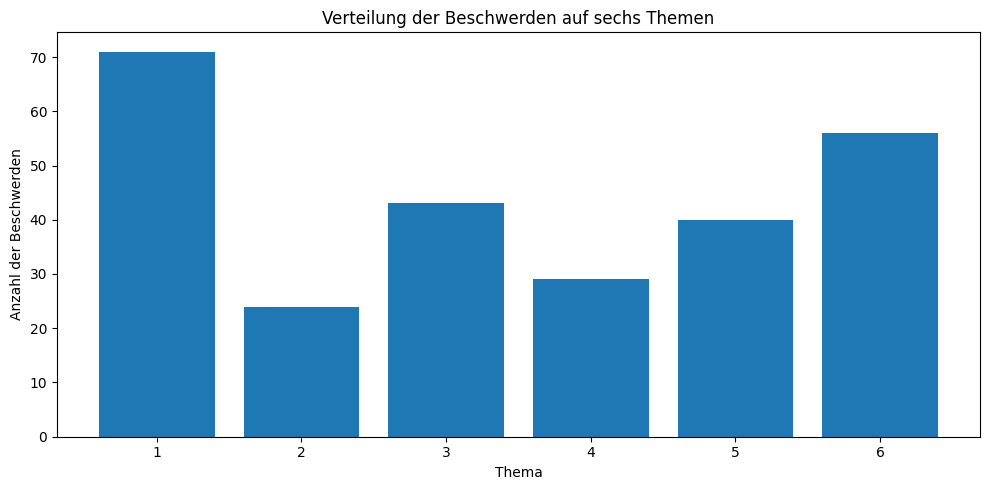

In [27]:
import matplotlib.pyplot as plt

# Balkendiagramm erstellen
plt.figure(figsize=(10, 5))

plt.bar(
    topic_results["Thema"].astype(str),
    topic_results["Anzahl Beschwerden"]
)

plt.title("Verteilung der Beschwerden auf sechs Themen")
plt.xlabel("Thema")
plt.ylabel("Anzahl der Beschwerden")

plt.tight_layout()
plt.show()

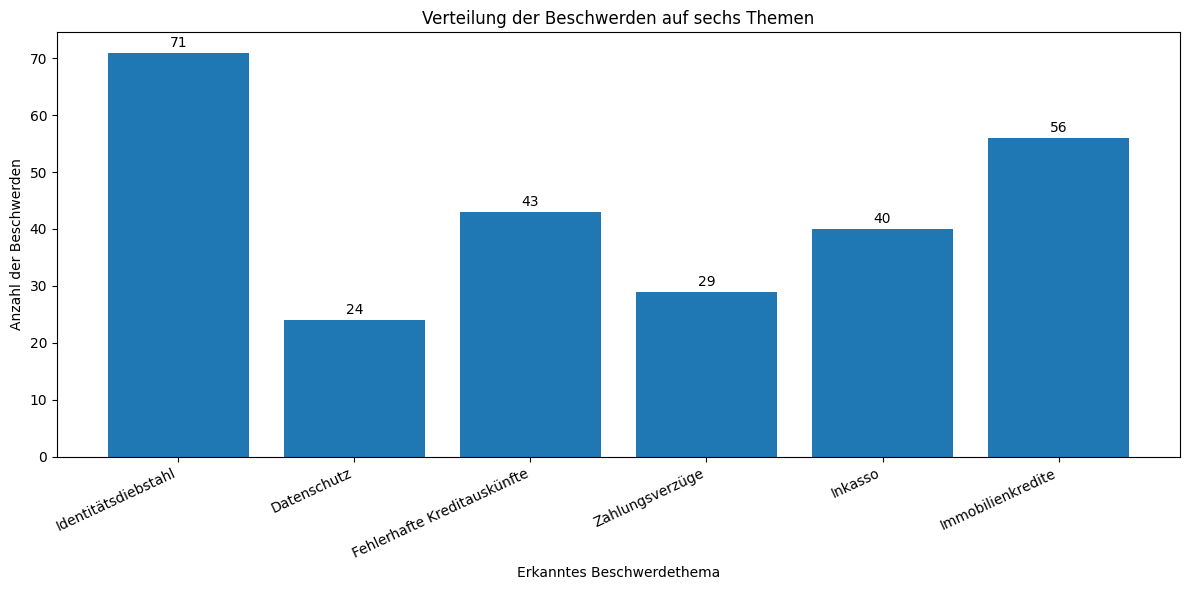

In [28]:
# Aussagekräftige Bezeichnungen für die sechs Themen
topic_names = [
    "Identitätsdiebstahl",
    "Datenschutz",
    "Fehlerhafte Kreditauskünfte",
    "Zahlungsverzüge",
    "Inkasso",
    "Immobilienkredite"
]

plt.figure(figsize=(12, 6))

bars = plt.bar(
    topic_names,
    topic_results["Anzahl Beschwerden"]
)

plt.title("Verteilung der Beschwerden auf sechs Themen")
plt.xlabel("Erkanntes Beschwerdethema")
plt.ylabel("Anzahl der Beschwerden")
plt.xticks(rotation=25, ha="right")

# Anzahl oberhalb der Balken anzeigen
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        int(bar.get_height()),
        ha="center"
    )

plt.tight_layout()

# Grafik zusätzlich speichern
plt.savefig("themenverteilung.png", dpi=300, bbox_inches="tight")

plt.show()

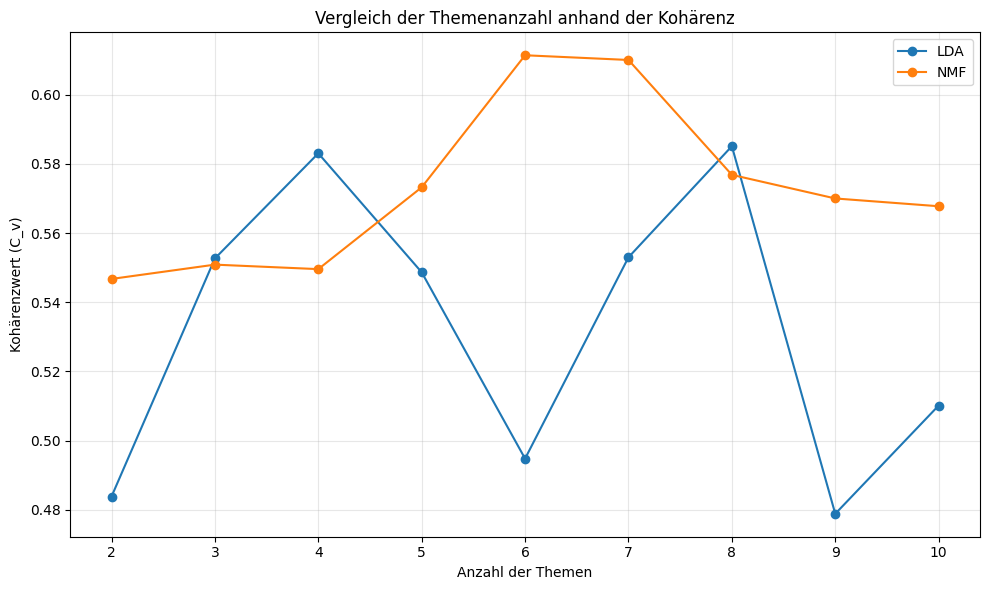

In [29]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(topic_range),
    lda_coherence,
    marker="o",
    label="LDA"
)

plt.plot(
    list(topic_range),
    nmf_coherence,
    marker="o",
    label="NMF"
)

plt.title("Vergleich der Themenanzahl anhand der Kohärenz")
plt.xlabel("Anzahl der Themen")
plt.ylabel("Kohärenzwert (C_v)")

plt.xticks(list(topic_range))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("kohaerenzvergleich.png", dpi=300, bbox_inches="tight")
plt.show()
